# 04 · Which genre is the book? (science fiction / fantasy / mystery-thriller)

**Why this task.** It uses real labels from the data and is the best candidate for a high accuracy: the title and especially the description usually say what kind of story it is.

**Label.** `genre_primary` from the subject-tag rules. To keep the label clean we use only books that match **exactly one** genre. The subject tags themselves are **hidden from the model** (the label is made from them).

**Tests.** Same books for every comparison, locked 15% test + 5-fold cross-validation, grouped by work:
* **G1** title only, **G2** title + creator (the same author appears in training and test, so this overstates new-book accuracy), **G3** title + year/pages (all on the single-genre books);
* on the books that have a description: **G4** title control, **G5** title + description, **G6** description only, **G7** title + creator + description.

Blurbs sometimes name the genre outright ("a fantasy"); that is legitimate content, but it explains part of the high score.

In [1]:
import warnings, os
warnings.filterwarnings("ignore")
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "2")       # be gentle with the laptop
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display

SEED = 2026
QUICK = False            # True = smaller/faster run (fewer trees, 3 folds)
N_FOLDS = 3 if QUICK else 5
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 180, "display.max_columns", 40, "display.max_rows", 200)

def find(name):
    """Local repo (notebooks/ or repo root) or, in Google Colab, ask for an upload."""
    for base in [Path("../data"), Path("data"), Path(".")]:
        if (base / name).exists():
            return base / name
    try:
        from google.colab import files
        print("Upload", name); files.upload()
        return Path(name)
    except ImportError:
        raise FileNotFoundError(name + " not found: run from notebooks/ in the repo or put the file next to the notebook")

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import TruncatedSVD
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

FL = ["genre_science_fiction", "genre_fantasy", "genre_mystery_thriller"]
def load(name):
    d = pd.read_csv(find(name), encoding="utf-8-sig")
    for c in FL: d[c] = d[c].astype(int)
    d = d[(d["sampling_stratum"] != "benchmark_random_fiction") & (d[FL].sum(axis=1) == 1)].reset_index(drop=True)
    d["title_creator"] = d["title"].fillna("") + " || " + d["first_creator"].fillna("")
    d["title_only"] = d["title"].fillna("")
    if "description" in d: d["description"] = d["description"].fillna("")
    return d
full, withd = load("training_api.csv"), load("training_with_descriptions.csv")
LABELS = ["science_fiction", "fantasy", "mystery_thriller"]
for n, d in (("single-genre books", full), ("... with description", withd)):
    print(n, len(d), d["genre_primary"].value_counts().to_dict(), "| always-the-commonest accuracy =", round(d["genre_primary"].value_counts(normalize=True).max(), 3))

single-genre books 5045 {'mystery_thriller': 1800, 'fantasy': 1770, 'science_fiction': 1475} | always-the-commonest accuracy = 0.357
... with description 2897 {'fantasy': 1111, 'mystery_thriller': 1020, 'science_fiction': 766} | always-the-commonest accuracy = 0.384


In [2]:
def make_pre(text_cols=("title_creator",), desc=False, nums=()):
    parts = [(c, TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True), c) for c in text_cols]
    if desc: parts.append(("desc", TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=8000, sublinear_tf=True, stop_words="english"), "description"))
    if nums: parts.append(("num", StandardScaler(), list(nums)))
    return ColumnTransformer(parts)
def model_zoo():
    return {
        "LogReg": lambda pre: Pipeline([("pre", pre), ("m", LogisticRegression(max_iter=3000, C=5))]),
        "LinearSVC": lambda pre: Pipeline([("pre", pre), ("m", LinearSVC(C=0.4))]),
        "HGB (on SVD of text)": lambda pre: Pipeline([("pre", pre), ("svd", TruncatedSVD(100 if not QUICK else 50, random_state=SEED)),
                                                       ("m", HistGradientBoostingClassifier(max_iter=120, learning_rate=0.06, random_state=SEED))]),
    }
def evaluate(d, label, pre_fn):
    y = d["genre_primary"].values
    pi, ti = next(StratifiedGroupKFold(7, shuffle=True, random_state=SEED).split(d, y, d["work_group"]))
    pool, test = d.iloc[pi].reset_index(drop=True), d.iloc[ti].reset_index(drop=True)
    yp, yt = pool["genre_primary"].values, test["genre_primary"].values
    rows, keep = [], {}
    for name, mk in model_zoo().items():
        oof = np.empty(len(pool), dtype=object)
        for tr, te in StratifiedGroupKFold(N_FOLDS, shuffle=True, random_state=SEED).split(pool, yp, pool["work_group"]):
            oof[te] = mk(pre_fn()).fit(pool.iloc[tr], yp[tr]).predict(pool.iloc[te])
        m = mk(pre_fn()).fit(pool, yp); pt = m.predict(test)
        rows.append({"data": label, "model": name, "CV accuracy": accuracy_score(yp, oof), "CV macro-F1": f1_score(yp, oof, average="macro"),
                     "TEST accuracy": accuracy_score(yt, pt), "TEST macro-F1": f1_score(yt, pt, average="macro"),
                     "baseline accuracy (commonest)": pd.Series(yt).value_counts(normalize=True).max()})
        keep[name] = (m, pt, yt, test)
    return pd.DataFrame(rows), keep
print("ready")

ready


## Books without description (G1–G3)

In [3]:
kept, res = {}, []
for label, pre_fn, d in [
    ("G1 title only",                lambda: make_pre(("title_only",)), full),
    ("G2 title + creator",           lambda: make_pre(("title_creator",)), full),
    ("G3 title + year/pages",        lambda: make_pre(("title_only",), nums=["publication_year", "scanned_page_count"]), full)]:
    r, k = evaluate(d, label, pre_fn); res.append(r); kept[label] = k; print(label, "done", flush=True)
resG = pd.concat(res, ignore_index=True); display(resG.round(3))

G1 title only done


G2 title + creator done


G3 title + year/pages done


,data,model,CV accuracy,CV macro-F1,TEST accuracy,TEST macro-F1,baseline accuracy (commonest)
0,G1 title only,LogReg,0.561,0.559,0.597,0.595,0.352
1,G1 title only,LinearSVC,0.564,0.558,0.586,0.582,0.352
2,G1 title only,HGB (on SVD of text),0.541,0.538,0.547,0.546,0.352
3,G2 title + creator,LogReg,0.647,0.644,0.691,0.689,0.352
4,G2 title + creator,LinearSVC,0.651,0.648,0.686,0.685,0.352
5,G2 title + creator,HGB (on SVD of text),0.582,0.576,0.605,0.603,0.352
6,G3 title + year/pages,LogReg,0.560,0.557,0.598,0.597,0.352
7,G3 title + year/pages,LinearSVC,0.566,0.562,0.589,0.587,0.352
8,G3 title + year/pages,HGB (on SVD of text),0.555,0.550,0.569,0.567,0.352


## Books with description (G4–G7), same books and split for every row

In [4]:
res = []
for label, pre_fn in [
    ("G4 title only (control)",              lambda: make_pre(("title_only",))),
    ("G5 title + DESCRIPTION",               lambda: make_pre(("title_only",), desc=True)),
    ("G6 description only",                  lambda: make_pre((), desc=True)),
    ("G7 title + creator + description",     lambda: make_pre(("title_creator",), desc=True))]:
    r, k = evaluate(withd, label, pre_fn); res.append(r); kept[label] = k; print(label, "done", flush=True)
resD = pd.concat(res, ignore_index=True); display(resD.round(3))

G4 title only (control) done


G5 title + DESCRIPTION done


G6 description only done


G7 title + creator + description done


,data,model,CV accuracy,CV macro-F1,TEST accuracy,TEST macro-F1,baseline accuracy (commonest)
0,G4 title only (control),LogReg,0.531,0.509,0.565,0.534,0.404
1,G4 title only (control),LinearSVC,0.539,0.515,0.569,0.537,0.404
2,G4 title only (control),HGB (on SVD of text),0.500,0.497,0.538,0.529,0.404
3,G5 title + DESCRIPTION,LogReg,0.764,0.757,0.768,0.756,0.404
4,G5 title + DESCRIPTION,LinearSVC,0.763,0.756,0.775,0.764,0.404
5,G5 title + DESCRIPTION,HGB (on SVD of text),0.697,0.688,0.770,0.759,0.404
6,G6 description only,LogReg,0.768,0.760,0.794,0.777,0.404
7,G6 description only,LinearSVC,0.770,0.762,0.804,0.788,0.404
8,G6 description only,HGB (on SVD of text),0.758,0.749,0.742,0.732,0.404
9,G7 title + creator + description,LogReg,0.775,0.770,0.809,0.797,0.404


## Best results

,data,model,CV accuracy,CV macro-F1,TEST accuracy,TEST macro-F1,baseline accuracy (commonest)
19,G7 title + creator + description,LinearSVC,0.780,0.774,0.816,0.804,0.404
18,G7 title + creator + description,LogReg,0.775,0.770,0.809,0.797,0.404
16,G6 description only,LinearSVC,0.770,0.762,0.804,0.788,0.404
15,G6 description only,LogReg,0.768,0.760,0.794,0.777,0.404
12,G5 title + DESCRIPTION,LogReg,0.764,0.757,0.768,0.756,0.404
13,G5 title + DESCRIPTION,LinearSVC,0.763,0.756,0.775,0.764,0.404
17,G6 description only,HGB (on SVD of text),0.758,0.749,0.742,0.732,0.404
20,G7 title + creator + description,HGB (on SVD of text),0.720,0.711,0.780,0.764,0.404


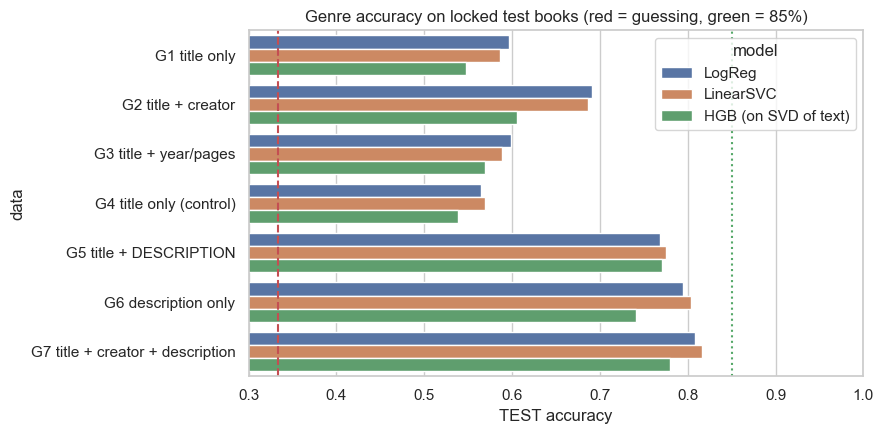

best by cross-validation: G7 title + creator + description / LinearSVC -> locked-test accuracy 0.816 macro-F1 0.804


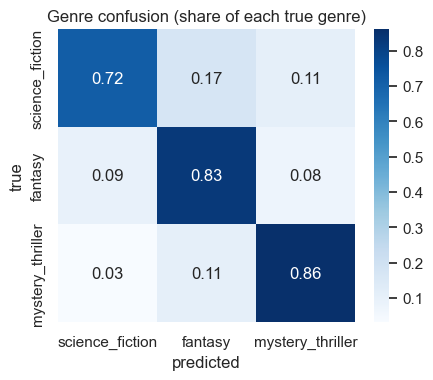

,title,genre_primary,description,predicted
12,Thunderbird Falls,science_fiction,"But no, Joanne's a reluctant shaman who last s...",fantasy
15,The hunger and ecstasy of vampires : a novel,science_fiction,"A professor recounts his time travels, one of ...",fantasy
19,Sturgeon is alive and well;,science_fiction,To here and the easel -- Slow sculpture -- It'...,mystery_thriller
21,Under the moons of Mars,science_fiction,A princess of Mars -- The gods of Mars -- The ...,fantasy
25,The children's hospital,science_fiction,Opens with the world ending under seven sudden...,fantasy
28,Puck of Pook's Hill,fantasy,Dan and Una perform their shortened version of...,mystery_thriller
41,Mugglenet.com's What will happen in Harry Pott...,fantasy,Citation key -- Foreword -- Book 7 basics -- S...,mystery_thriller
43,Moon boy. Vol. 6,fantasy,"1 v. (unpaged) : 21 cm ""The Black Rabbit disap...",science_fiction


In [5]:
allr = pd.concat([resG, resD], ignore_index=True)
display(allr.sort_values("CV macro-F1", ascending=False).head(8).round(3))
fig, ax = plt.subplots(figsize=(9, 4.5)); sns.barplot(data=allr, y="data", x="TEST accuracy", hue="model", ax=ax); ax.axvline(1/3, color="r", ls="--"); ax.axvline(0.85, color="g", ls=":")
ax.set_xlim(0.3, 1); ax.set_title("Genre accuracy on locked test books (red = guessing, green = 85%)"); plt.tight_layout(); plt.show()
best = allr.sort_values("CV macro-F1", ascending=False).iloc[0]
print("best by cross-validation:", best["data"], "/", best["model"], "-> locked-test accuracy", round(best["TEST accuracy"], 3), "macro-F1", round(best["TEST macro-F1"], 3))
m, pt, yt, test = kept[best["data"]][best["model"]]
cm = confusion_matrix(yt, pt, labels=LABELS, normalize="true")
plt.figure(figsize=(4.8, 3.8)); sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=LABELS, yticklabels=LABELS); plt.xlabel("predicted"); plt.ylabel("true"); plt.title("Genre confusion (share of each true genre)"); plt.show()
wrong = test[pt != yt].head(8)
cols = ["title", "genre_primary"] + (["description"] if "description" in test else [])
w = wrong[cols].assign(predicted=pt[pt != yt][:8])
if "description" in w: w["description"] = w["description"].str[:140]
display(w)

## Summary
* Genre from the **title alone** is only moderately accurate; the **description** is what makes high accuracy possible (compare G4 with G5/G6).
* The remaining errors are mostly science fiction vs fantasy, where the genres genuinely overlap (and the label comes from the cataloguer's tags).
* This is the kind of task where the data really contains the answer, so it is a good example of a model that works well; popularity is the opposite case.